# OCR + NLP sobre noticias de periódicos peruanos
**Curso:** Ciencia de Datos II — Examen de medio curso

**Problema:** los periódicos impresos peruanos concentran información de interés público (política, economía, seguridad ciudadana, deportes), pero en papel no puede buscarse, clasificarse ni analizarse a escala. Este proyecto construye un pipeline que **fotografía una nota de periódico, extrae su texto con OCR y la analiza con NLP**: clasificación temática, extracción de entidades (personas, instituciones y regiones del Perú), palabras clave, resumen automático y nube de palabras.

| Etapa | Técnicas |
|---|---|
| Preprocesamiento de imagen | Escala de grises, redimensionamiento, corrección de inclinación, eliminación de ruido, eliminación de sombras, CLAHE, binarización Otsu / adaptativa |
| OCR | Tesseract (pytesseract) vs EasyOCR, evaluados con CER y WER |
| Limpieza de texto | Reparación de guiones y saltos, minúsculas, caracteres especiales, tokenización, stopwords, lematización |
| NLP | Clasificación (TF-IDF + modelos clásicos vs zero-shot), NER, palabras clave, resumen extractivo, nube de palabras |

> Ejecutar con **GPU** (Entorno de ejecución → Cambiar tipo → T4 GPU) para que EasyOCR y el modelo zero-shot sean rápidos.

## 0. Instalación

In [1]:
!apt-get install -y -qq tesseract-ocr tesseract-ocr-spa > /dev/null
!pip install -q pytesseract easyocr jiwer pymupdf wordcloud
!python -m spacy download es_core_news_md -q
!tesseract --list-langs

✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
List of available languages in "/usr/share/tesseract-ocr/5/tessdata/" (3):
eng
osd
spa


## 1. Datos

**Estructura en Google Drive** (la etiqueta sale del nombre del archivo = sección del periódico):
```
CDII_OCR_Periodicos/
├── data/raw/            politica_11.jpeg, deporte_5.jpeg, policial_4.jpeg, ...
├── data/ground_truth/   politica_11.txt   (transcripción manual de ~10 imágenes)
├── outputs/
└── modelos/
```
Formato del nombre: `seccion_numero.ext` (ej. `politica_11.jpeg`, `policial_4.jpeg`) · secciones: `politica`, `economia`, `policial`, `deporte`, `espectaculo`.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

BASE = Path('/content/drive/My Drive/Universidad/10mo ciclo/CDII/CDII_OCR_Periodicos')
RAW, GT = BASE / 'data/raw', BASE / 'data/ground_truth'
OUT, MOD = BASE / 'outputs', BASE / 'modelos'

for p in [RAW, GT, OUT, MOD]:
    p.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


### Módulo compartido
Este mismo archivo se sube a GitHub y lo importa la app de Streamlit, así el notebook y la app aplican exactamente el mismo pipeline.

In [3]:
%%writefile utils_ocr_nlp.py
"""
utils_ocr_nlp.py
Funciones compartidas entre el notebook de Colab y la app de Streamlit.
Proyecto: OCR + NLP sobre noticias de periódicos peruanos.
"""
import re
import unicodedata
from collections import Counter

import cv2
import numpy as np
import pytesseract

# =====================================================================
# 1. CARGA DE IMÁGENES (JPG, PNG y PDF escaneado)
# =====================================================================
def cargar_desde_bytes(datos: bytes, nombre: str = ""):
    """Devuelve una lista de imágenes BGR (una por página si es PDF)."""
    if nombre.lower().endswith(".pdf"):
        import fitz  # PyMuPDF
        paginas = []
        with fitz.open(stream=datos, filetype="pdf") as doc:
            for pag in doc:
                pix = pag.get_pixmap(dpi=300)
                img = np.frombuffer(pix.samples, np.uint8).reshape(pix.h, pix.w, pix.n)
                img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR if pix.n == 3 else cv2.COLOR_RGBA2BGR)
                paginas.append(img)
        return paginas
    img = cv2.imdecode(np.frombuffer(datos, np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError("No se pudo leer la imagen")
    return [img]


# =====================================================================
# 2. PREPROCESAMIENTO DE IMÁGENES
# =====================================================================
def a_gris(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img


def redimensionar(gray, ancho_objetivo=2000):
    """Tesseract rinde mejor con letras de ~25-35 px de alto.
    Agranda fotos pequeñas (INTER_CUBIC) y reduce las enormes (INTER_AREA)."""
    h, w = gray.shape[:2]
    escala = ancho_objetivo / w
    if 0.9 < escala < 1.1:
        return gray
    interp = cv2.INTER_CUBIC if escala > 1 else cv2.INTER_AREA
    return cv2.resize(gray, None, fx=escala, fy=escala, interpolation=interp)


def corregir_inclinacion(gray, max_angulo=6, paso=0.5):
    """Endereza la foto buscando el ángulo que maximiza la nitidez
    del perfil de proyección horizontal (las líneas de texto)."""
    peq = cv2.resize(gray, (800, int(800 * gray.shape[0] / gray.shape[1])))
    _, binv = cv2.threshold(peq, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    centro = (binv.shape[1] // 2, binv.shape[0] // 2)
    mejor_ang, mejor_score = 0.0, -1
    for ang in np.arange(-max_angulo, max_angulo + paso, paso):
        M = cv2.getRotationMatrix2D(centro, ang, 1.0)
        rot = cv2.warpAffine(binv, M, (binv.shape[1], binv.shape[0]), borderValue=0)
        perfil = rot.sum(axis=1).astype(np.float64)
        score = np.sum((perfil[1:] - perfil[:-1]) ** 2)
        if score > mejor_score:
            mejor_ang, mejor_score = ang, score
    if mejor_ang == 0:
        return gray
    h, w = gray.shape
    M = cv2.getRotationMatrix2D((w // 2, h // 2), mejor_ang, 1.0)
    fondo = int(np.median(gray))  # rellena bordes con el color del papel
    return cv2.warpAffine(gray, M, (w, h), flags=cv2.INTER_CUBIC,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=fondo)


def eliminar_ruido(gray, h=10):
    return cv2.fastNlMeansDenoising(gray, None, h=h, templateWindowSize=7, searchWindowSize=21)


def quitar_sombras(gray, k=31):
    """Normalización de fondo: estima la iluminación del papel con un
    cierre morfológico + desenfoque y la divide. Elimina sombras y degradados."""
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    fondo = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, kernel)
    fondo = cv2.medianBlur(fondo, k if k % 2 else k + 1)
    norm = cv2.divide(gray, fondo, scale=255)
    return cv2.normalize(norm, None, 0, 255, cv2.NORM_MINMAX)


def mejorar_contraste(gray, clip=1.5):
    """CLAHE: ecualización adaptativa, corrige sombras e iluminación irregular."""
    return cv2.createCLAHE(clipLimit=clip, tileGridSize=(8, 8)).apply(gray)


def binarizar(gray, metodo="adaptativa"):
    if metodo == "otsu":
        blur = cv2.GaussianBlur(gray, (5, 5), 0)
        _, b = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        return b
    if metodo == "adaptativa":
        bloque = max(31, (gray.shape[1] // 40) | 1)       # impar y proporcional
        b = cv2.adaptiveThreshold(cv2.medianBlur(gray, 3), 255,
                                  cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                  cv2.THRESH_BINARY, bloque, 20)
        return quitar_motas(b)
    return gray


def quitar_motas(binaria, area_min=40):
    """Elimina puntos negros aislados (ruido) tras binarizar."""
    inv = 255 - binaria
    n, lab, stats, _ = cv2.connectedComponentsWithStats(inv, connectivity=8)
    limpio = np.zeros_like(inv)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= area_min:
            limpio[lab == i] = 255
    return 255 - limpio


def preprocesar(img, redim=True, enderezar=True, ruido=True, sombras=True,
                contraste=False, binarizacion="otsu"):
    """Pipeline completo. Devuelve (imagen_final, dict_de_etapas)."""
    etapas = {"original": img}
    g = a_gris(img);                      etapas["gris"] = g
    if redim:     g = redimensionar(g);   etapas["redimensionada"] = g
    if enderezar: g = corregir_inclinacion(g); etapas["enderezada"] = g
    if ruido:     g = eliminar_ruido(g);  etapas["sin_ruido"] = g
    if sombras:   g = quitar_sombras(g);  etapas["sin_sombras"] = g
    if contraste: g = mejorar_contraste(g); etapas["contraste"] = g
    if binarizacion:
        g = binarizar(g, binarizacion);   etapas[f"binarizada_{binarizacion}"] = g
    return g, etapas


# Variantes para el experimento (qué paso aporta realmente)
_B = dict(redim=False, enderezar=False, ruido=False, sombras=False, contraste=False, binarizacion=None)
VARIANTES = {
    "V0_solo_gris":        {**_B},
    "V1_+redim":           {**_B, "redim": True},
    "V2_+enderezar":       {**_B, "redim": True, "enderezar": True},
    "V3_+ruido":           {**_B, "redim": True, "enderezar": True, "ruido": True},
    "V4_+sombras":         {**_B, "redim": True, "enderezar": True, "ruido": True, "sombras": True},
    "V5_+CLAHE":           {**_B, "redim": True, "enderezar": True, "ruido": True, "sombras": True, "contraste": True},
    "V6_+otsu":            {**_B, "redim": True, "enderezar": True, "ruido": True, "sombras": True, "binarizacion": "otsu"},
    "V7_+adaptativa":      {**_B, "redim": True, "enderezar": True, "ruido": True, "sombras": True, "binarizacion": "adaptativa"},
}


# =====================================================================
# 3. OCR
# =====================================================================
def ocr_tesseract(img, psm=3):
    """psm 3 = segmentación automática (bueno para columnas de periódico)."""
    return pytesseract.image_to_string(img, lang="spa", config=f"--oem 3 --psm {psm}")


def confianza_tesseract(img, psm=3):
    """Confianza media (0-100) de las palabras reconocidas."""
    d = pytesseract.image_to_data(img, lang="spa", config=f"--oem 3 --psm {psm}",
                                  output_type=pytesseract.Output.DICT)
    confs = [float(c) for c, t in zip(d["conf"], d["text"]) if float(c) >= 0 and t.strip()]
    return float(np.mean(confs)) if confs else 0.0


# =====================================================================
# 4. LIMPIEZA DE TEXTO
# =====================================================================
def reparar_texto_ocr(texto):
    """Corrige artefactos típicos del OCR en periódicos, conservando
    mayúsculas y puntuación (útil para NER, resumen y clasificador)."""
    t = unicodedata.normalize("NFC", texto)
    t = t.replace("\x0c", "\n")
    t = re.sub(r"[“”«»„]", '"', t)
    t = re.sub(r"[‘’´`]", "'", t)
    t = re.sub(r"[—–]", "-", t)
    # palabras cortadas al final de línea: "presi-\ndente" -> "presidente"
    t = re.sub(r"(\w)-\s*\n\s*(\w)", r"\1\2", t)
    # basura frecuente: |, ~, _, ^, •, etc.
    t = re.sub(r"[|~_^•■□▪¦\\{}<>]", " ", t)
    # saltos simples dentro de un párrafo -> espacio; dobles = párrafo
    t = re.sub(r"\n{2,}", "<<P>>", t)
    t = re.sub(r"\s*\n\s*", " ", t)
    t = t.replace("<<P>>", "\n\n")
    # falso salto de párrafo: la línea no cerró oración y la siguiente va en minúscula
    t = re.sub(r'([^.!?:"])\s*\n\n\s*(?=[a-záéíóúüñ0-9(])', r"\1 ", t)
    # espacios antes de signos y espacios múltiples
    t = re.sub(r"\s+([,.;:!?)])", r"\1", t)
    t = re.sub(r"[ \t]{2,}", " ", t)
    # líneas de 1-2 caracteres (ruido de bordes/fotos)
    lineas = [l.strip() for l in t.split("\n") if len(l.strip()) > 2 or l.strip() == ""]
    return "\n".join(lineas).strip()


def limpiar_texto(texto):
    """Minúsculas + solo letras (con tildes y ñ), números y espacios."""
    t = texto.lower()
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"[^a-záéíóúüñ0-9\s]", " ", t)
    t = re.sub(r"\b\d+\b", " ", t)          # números sueltos
    return re.sub(r"\s+", " ", t).strip()


STOPWORDS_EXTRA = {
    "según", "además", "dijo", "indicó", "señaló", "afirmó", "explicó", "precisó",
    "año", "años", "día", "días", "vez", "ser", "haber", "tener", "hacer", "poder",
    "decir", "ir", "así", "solo", "sólo", "mismo", "misma", "pues", "embargo",
    "foto", "difusión", "redacción", "nota", "página",
}


def tokenizar(texto_limpio, nlp, lematizar=True):
    """Tokens sin stopwords, con lematización de spaCy."""
    doc = nlp(texto_limpio)
    toks = []
    for t in doc:
        if not t.is_alpha or t.is_stop or len(t.text) <= 2:
            continue
        palabra = t.lemma_.lower() if lematizar else t.text
        if palabra not in STOPWORDS_EXTRA:
            toks.append(palabra)
    return toks


# =====================================================================
# 5. NLP
# =====================================================================
REGIONES_PERU = [
    "Amazonas", "Áncash", "Apurímac", "Arequipa", "Ayacucho", "Cajamarca", "Callao",
    "Cusco", "Huancavelica", "Huánuco", "Ica", "Junín", "La Libertad", "Lambayeque",
    "Lima", "Loreto", "Madre de Dios", "Moquegua", "Pasco", "Piura", "Puno",
    "San Martín", "Tacna", "Tumbes", "Ucayali",
]


def _sin_tildes(s):
    return "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")


def regiones_mencionadas(texto):
    t = _sin_tildes(texto.lower())
    return [r for r in REGIONES_PERU
            if re.search(rf"\b{re.escape(_sin_tildes(r.lower()))}\b", t)]


def extraer_entidades(texto_reparado, nlp):
    """NER de spaCy (PER, LOC, ORG, MISC) + regiones del Perú."""
    doc = nlp(texto_reparado)
    ents = {"PER": Counter(), "LOC": Counter(), "ORG": Counter(), "MISC": Counter()}
    for e in doc.ents:
        txt = e.text.strip()
        if e.label_ in ents and len(txt) > 2 and not txt.isdigit():
            ents[e.label_][txt] += 1
    ents = {k: v.most_common(10) for k, v in ents.items()}
    ents["REGIONES_PERU"] = regiones_mencionadas(texto_reparado)
    return ents


def resumen_extractivo(texto_reparado, nlp, n_oraciones=3):
    """Resumen por frecuencia de palabras: elige las oraciones con mayor
    puntaje y las devuelve en su orden original. Robusto a errores de OCR."""
    doc = nlp(texto_reparado)
    oraciones = [s for s in doc.sents if len([t for t in s if t.is_alpha]) >= 6]
    if len(oraciones) <= n_oraciones:
        return " ".join(s.text.strip() for s in oraciones)
    freq = Counter(t.lemma_.lower() for t in doc
                   if t.is_alpha and not t.is_stop and len(t.text) > 2)
    maxf = max(freq.values()) if freq else 1
    puntajes = []
    for i, s in enumerate(oraciones):
        palabras = [t.lemma_.lower() for t in s if t.is_alpha and not t.is_stop]
        p = sum(freq[w] / maxf for w in palabras) / (len(palabras) ** 0.5 + 1e-9)
        puntajes.append((p, i))
    elegidas = sorted(i for _, i in sorted(puntajes, reverse=True)[:n_oraciones])
    return " ".join(oraciones[i].text.strip() for i in elegidas)


def palabras_clave(texto_tokens_unidos, vectorizador, n=10):
    """Top-n términos por TF-IDF usando el vectorizador entrenado con el corpus."""
    v = vectorizador.transform([texto_tokens_unidos]).toarray()[0]
    vocab = np.array(vectorizador.get_feature_names_out())
    idx = v.argsort()[::-1][:n]
    return [(vocab[i], round(float(v[i]), 3)) for i in idx if v[i] > 0]


# =====================================================================
# 6. MÉTRICAS DE OCR
# =====================================================================
def normalizar_para_metrica(t):
    t = unicodedata.normalize("NFC", t.lower())
    t = re.sub(r"(\w)-\s*\n\s*(\w)", r"\1\2", t)
    return re.sub(r"\s+", " ", t).strip()


def metricas_ocr(referencia, prediccion):
    import jiwer
    r, p = normalizar_para_metrica(referencia), normalizar_para_metrica(prediccion)
    return {"CER": jiwer.cer(r, p), "WER": jiwer.wer(r, p)}

Writing utils_ocr_nlp.py


In [4]:
import importlib, utils_ocr_nlp as U; importlib.reload(U)
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, time, json, spacy
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 110
nlp = spacy.load('es_core_news_md')
!cp utils_ocr_nlp.py "{BASE}/utils_ocr_nlp.py"

82 imágenes | 9 con transcripción manual
seccion
deporte        23
espectaculo    22
policial       18
politica       13
economia        6
Name: count, dtype: int64


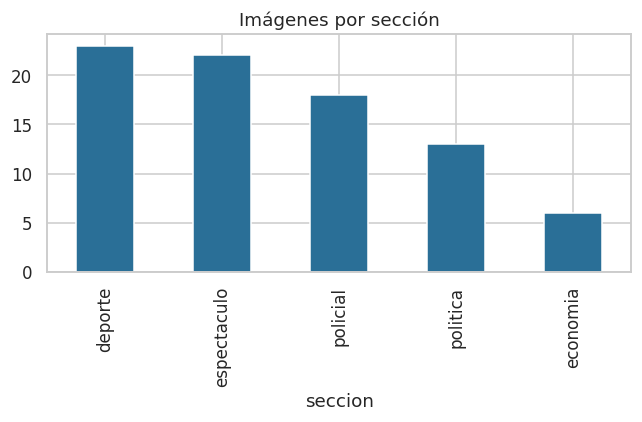

In [5]:
EXT = {'.jpg', '.jpeg', '.png', '.pdf'}
filas = []
for f in sorted(RAW.iterdir()):
    if f.suffix.lower() not in EXT: continue
    partes = f.stem.lower().split('_')
    filas.append({'archivo': f.name, 'ruta': str(f), 'seccion': partes[0],
                  'diario': partes[1] if len(partes) >= 3 else 'sin_dato',   # solo si usan seccion_diario_num
                  'tiene_gt': (GT/f'{f.stem}.txt').exists()})
df = pd.DataFrame(filas)
print(f'{len(df)} imágenes | {df.tiene_gt.sum()} con transcripción manual')

print(df.seccion.value_counts())   # revisar que no haya secciones mal escritas
VARIOS_DIARIOS = df.diario.nunique() > 1
fig, ax = plt.subplots(1, 2 if VARIOS_DIARIOS else 1, figsize=(12 if VARIOS_DIARIOS else 6, 4))
ax = np.atleast_1d(ax)
df.seccion.value_counts().plot.bar(ax=ax[0], color='#2a6f97', title='Imágenes por sección')
if VARIOS_DIARIOS:
    pd.crosstab(df.diario, df.seccion).plot.bar(stacked=True, ax=ax[1], title='Sección por diario')
plt.tight_layout(); plt.show()

In [6]:
# Características de las imágenes (resolución, brillo, nitidez)
def info_img(r):
    img = U.cargar_desde_bytes(open(r, 'rb').read(), r)[0]; g = U.a_gris(img)
    return pd.Series({'ancho': g.shape[1], 'alto': g.shape[0], 'brillo': g.mean(),
                      'nitidez': cv2.Laplacian(g, cv2.CV_64F).var()})
df = pd.concat([df, df.ruta.apply(info_img)], axis=1)
df[['ancho', 'alto', 'brillo', 'nitidez']].describe().round(1)
df[df.ancho < 1200][['archivo', 'ancho', 'alto']].sort_values('ancho')

,archivo,ancho,alto
0,deporte_1.jpeg,223.0,758.0
22,deporte_9.jpeg,254.0,371.0
31,espectaculo_11.jpeg,263.0,570.0
44,espectaculo_3.jpeg,268.0,779.0
50,espectaculo_9.jpeg,272.0,1156.0
...,...,...,...
37,espectaculo_17.jpeg,1120.0,636.0
23,economia_1.png,1151.0,827.0
8,deporte_17.jpeg,1164.0,756.0
40,espectaculo_2.jpeg,1172.0,466.0


## 2. Preprocesamiento de imágenes

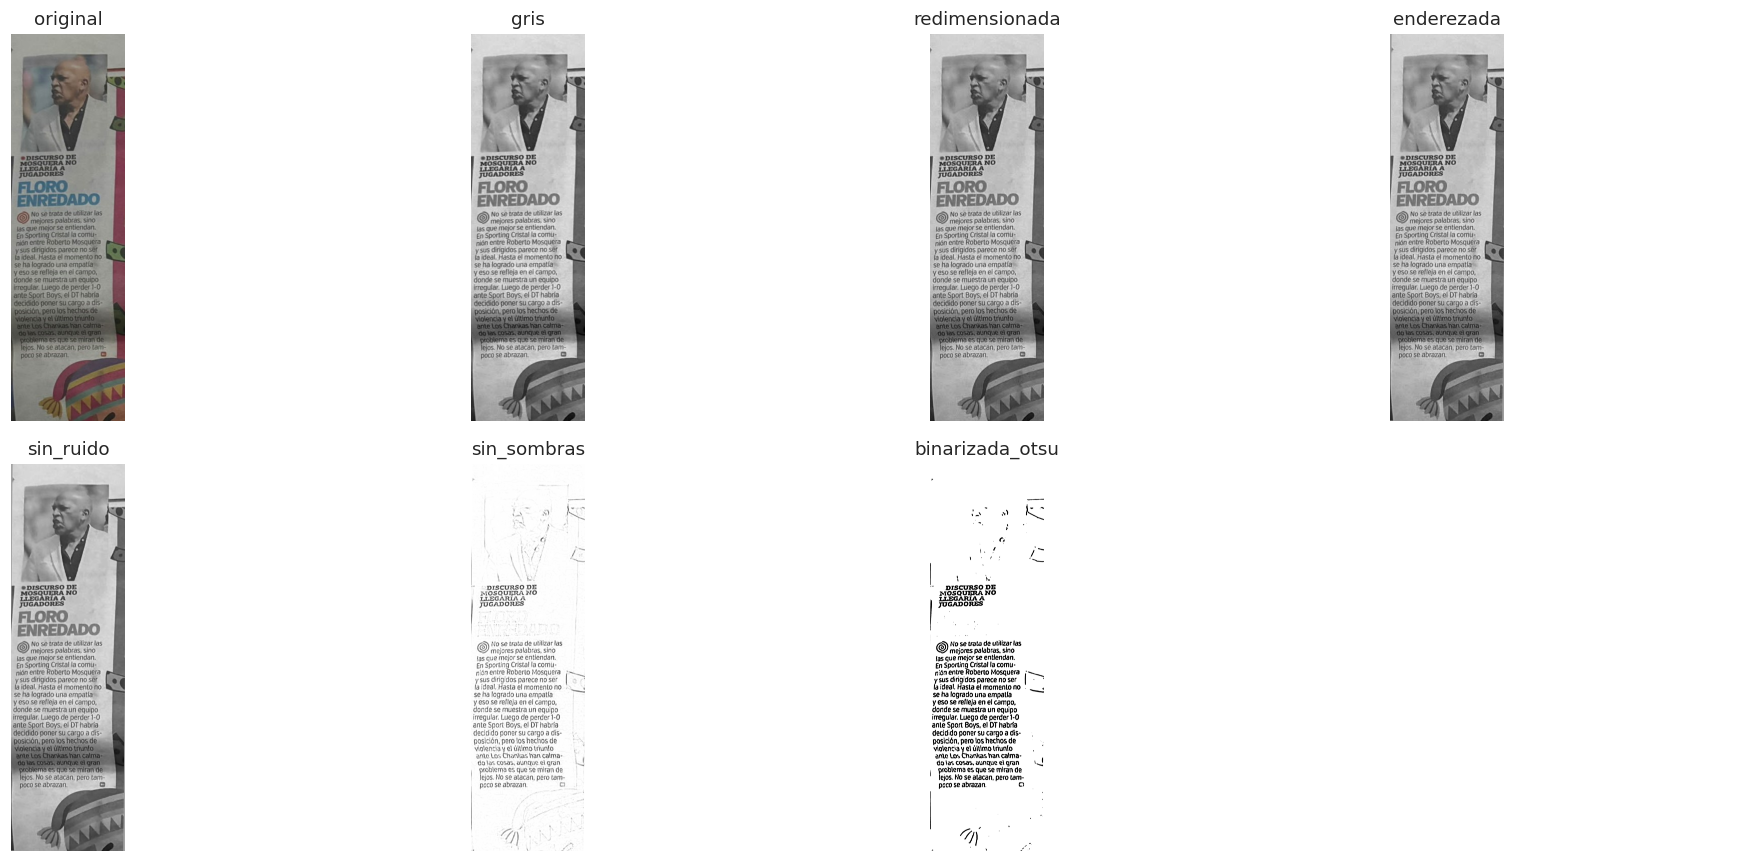

In [7]:
def mostrar_etapas(ruta, **cfg):
    img = U.cargar_desde_bytes(open(ruta, 'rb').read(), ruta)[0]
    _, et = U.preprocesar(img, **cfg)
    fig, axs = plt.subplots(2, (len(et) + 1) // 2, figsize=(18, 8))
    for ax, (nom, im) in zip(axs.ravel(), et.items()):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap='gray')
        ax.set_title(nom); ax.axis('off')
    for ax in axs.ravel()[len(et):]: ax.axis('off')
    plt.tight_layout(); plt.show()

# Elijan una foto "difícil" (sombra, inclinación, poca luz) para mostrarla en la exposición
mostrar_etapas(df.ruta.iloc[0])

### 2.1 Experimento: ¿qué paso de preprocesamiento mejora realmente el OCR?
Se agregan pasos de forma acumulativa (V0 → V7) y se mide contra la transcripción manual:
- **CER** (Character Error Rate) y **WER** (Word Error Rate): menor es mejor.
- **Confianza** media de Tesseract (0–100), útil cuando no hay transcripción.

,CER,WER,confianza,tiempo_s
variante,,,,
V0_solo_gris,0.556,0.735,62.046,0.931
V1_+redim,0.545,0.727,71.893,2.382
V2_+enderezar,0.575,0.753,70.924,2.356
V3_+ruido,0.627,0.797,74.180,6.942
V4_+sombras,0.442,0.716,76.376,7.299
V5_+CLAHE,0.576,0.861,69.080,7.205
V6_+otsu,0.567,0.815,69.833,7.338
V7_+adaptativa,0.592,0.963,67.688,10.026


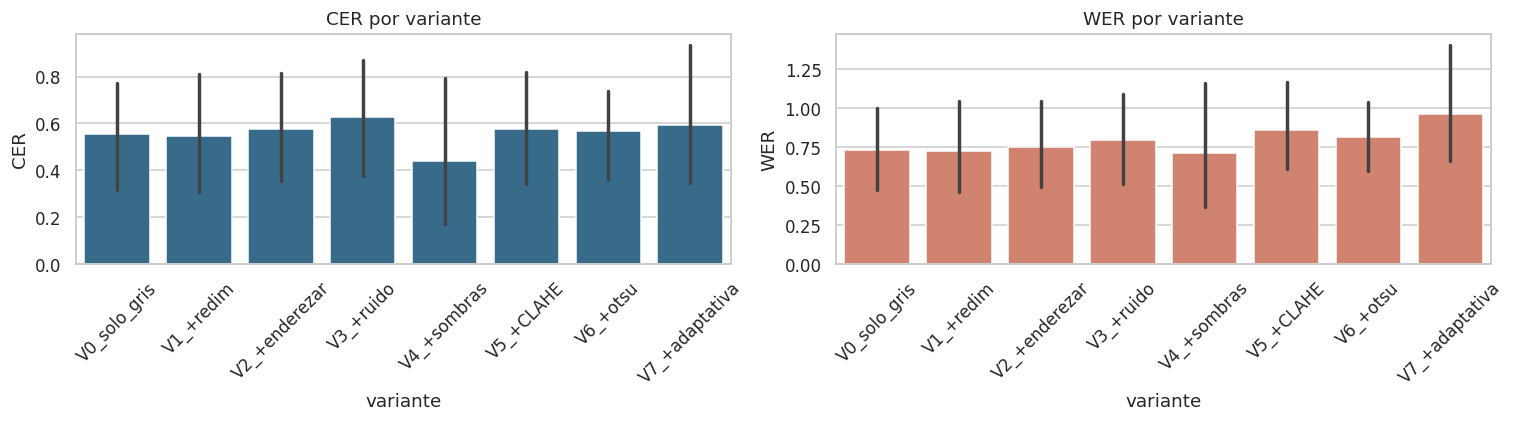

Mejor variante: V4_+sombras {'redim': True, 'enderezar': True, 'ruido': True, 'sombras': True, 'contraste': False, 'binarizacion': None}


In [8]:
sub = df[df.tiene_gt]
assert len(sub) > 0, 'Transcriban a mano al menos 8-10 imágenes en data/ground_truth/'
res = []
for _, r in sub.iterrows():
    img = U.cargar_desde_bytes(open(r.ruta, 'rb').read(), r.ruta)[0]
    ref = (GT/f"{Path(r.archivo).stem}.txt").read_text(encoding='utf-8')
    for var, cfg in U.VARIANTES.items():
        t0 = time.time(); proc, _ = U.preprocesar(img, **cfg); txt = U.ocr_tesseract(proc)
        res.append({'archivo': r.archivo, 'variante': var, 'tiempo_s': time.time() - t0,
                    'confianza': U.confianza_tesseract(proc), **U.metricas_ocr(ref, txt)})
exp = pd.DataFrame(res)
tabla_var = exp.groupby('variante')[['CER', 'WER', 'confianza', 'tiempo_s']].mean().round(3)
display(tabla_var)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=exp, x='variante', y='CER', ax=ax[0], color='#2a6f97'); ax[0].set_title('CER por variante')
sns.barplot(data=exp, x='variante', y='WER', ax=ax[1], color='#e07a5f'); ax[1].set_title('WER por variante')
for a in ax: a.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

MEJOR = tabla_var.CER.idxmin(); CFG = U.VARIANTES[MEJOR]
print('Mejor variante:', MEJOR, CFG)

### 2.2 Tesseract vs EasyOCR

In [9]:
import easyocr
reader = easyocr.Reader(['es'], gpu=True)
comp = []
for _, r in sub.iterrows():
    img = U.cargar_desde_bytes(open(r.ruta, 'rb').read(), r.ruta)[0]
    ref = (GT/f"{Path(r.archivo).stem}.txt").read_text(encoding='utf-8')
    proc, _ = U.preprocesar(img, **CFG)
    for motor, entrada in [('Tesseract', proc), ('EasyOCR', proc), ('EasyOCR_sin_prep', U.a_gris(img))]:
        t0 = time.time()
        txt = U.ocr_tesseract(entrada) if motor == 'Tesseract' else \
              '\n'.join(reader.readtext(entrada, detail=0, paragraph=True))
        comp.append({'motor': motor, 'tiempo_s': time.time() - t0, **U.metricas_ocr(ref, txt)})
pd.DataFrame(comp).groupby('motor').mean().round(3)

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

,tiempo_s,CER,WER
motor,,,
EasyOCR,1.984,0.500,0.845
EasyOCR_sin_prep,0.665,0.512,0.866
Tesseract,2.548,0.442,0.716


> **Decisión de despliegue:** si la diferencia de CER es pequeña, se despliega Tesseract: es más liviano (EasyOCR requiere PyTorch, que suele exceder la memoria de Streamlit Community Cloud).

## 3. OCR de todo el dataset

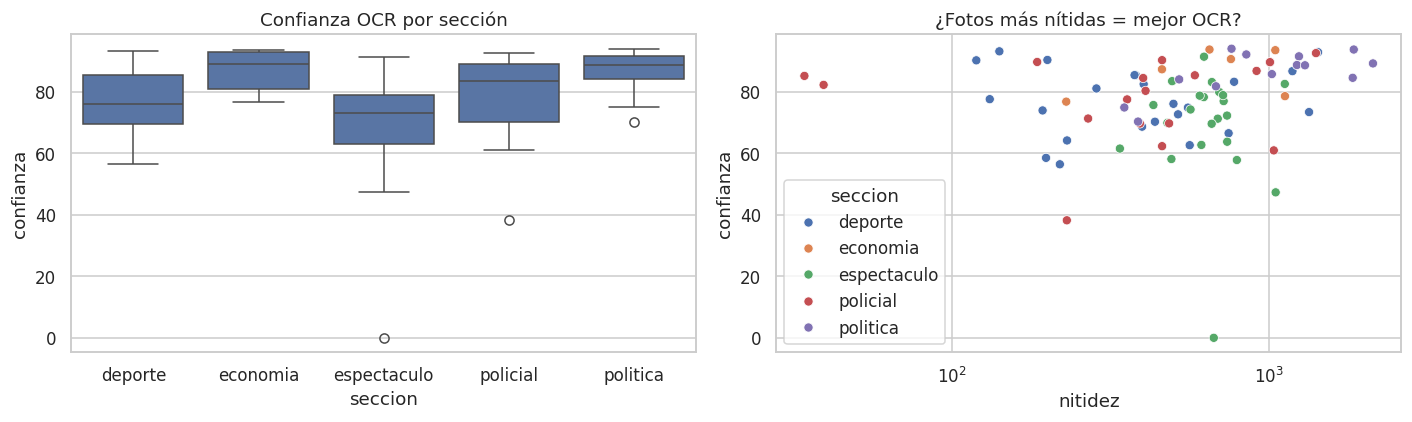

In [10]:
textos = []
for _, r in df.iterrows():
    paginas = U.cargar_desde_bytes(open(r.ruta, 'rb').read(), r.ruta)
    crudo, confs = [], []
    for img in paginas:
        proc, _ = U.preprocesar(img, **CFG)
        crudo.append(U.ocr_tesseract(proc)); confs.append(U.confianza_tesseract(proc))
    textos.append({'texto_crudo': '\n\n'.join(crudo), 'confianza': np.mean(confs)})
df = pd.concat([df.drop(columns=['texto_crudo', 'confianza'], errors='ignore'),
                pd.DataFrame(textos)], axis=1)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x='diario' if VARIOS_DIARIOS else 'seccion', y='confianza', ax=ax[0])
ax[0].set_title('Confianza OCR por ' + ('diario' if VARIOS_DIARIOS else 'sección'))
sns.scatterplot(data=df, x='nitidez', y='confianza', hue='seccion', ax=ax[1]); ax[1].set_xscale('log')
ax[1].set_title('¿Fotos más nítidas = mejor OCR?')
plt.tight_layout(); plt.show()
df.to_csv(OUT/'ocr_crudo.csv', index=False)

## 4. Limpieza y preprocesamiento del texto

In [11]:
df['texto_reparado'] = df.texto_crudo.apply(U.reparar_texto_ocr)   # para NER y resumen
df['texto_limpio']   = df.texto_reparado.apply(U.limpiar_texto)    # minúsculas, sin símbolos
df['tokens']         = df.texto_limpio.apply(lambda t: U.tokenizar(t, nlp))  # sin stopwords + lemas
df['tokens_str']     = df.tokens.str.join(' ')
df['n_palabras']     = df.texto_limpio.str.split().str.len()
df['n_tokens']       = df.tokens.str.len()

ej = df.iloc[0]
for nom in ['texto_crudo', 'texto_reparado', 'texto_limpio']:
    print(f'===== {nom} =====\n{ej[nom][:500]}\n')
print('===== tokens =====\n', ej.tokens[:40])

===== texto_crudo =====
PS y)

> y

-DISCURSO DE
MOSQUERA. NO

TS CADORES

|
/

No se trata de utilizar las

O mejores palabras, sino
las que mejor se entiendan.

En Sporting Cristal la comu-

nión entre Roberto Mosquera A

be dinaidos parece no ser
a ideal. Hasta el momento no
se ha logrado una empatía

y eso se refleja en el campo,
donde se muestra un equipo

irregular. Luego de perder 1-0

ante Spori Boys, el DT habría

decidido poner su cargo a dis-

posición, pero los hechos de
wolencia y el último triunfo

ante L

===== texto_reparado =====
PS y) y

-DISCURSO DE MOSQUERA. NO

TS CADORES


No se trata de utilizar las

O mejores palabras, sino las que mejor se entiendan.

En Sporting Cristal la comunión entre Roberto Mosquera A be dinaidos parece no ser a ideal. Hasta el momento no se ha logrado una empatía y eso se refleja en el campo, donde se muestra un equipo irregular. Luego de perder 1-0 ante Spori Boys, el DT habría decidido poner su cargo a disposición, pero los hechos de w

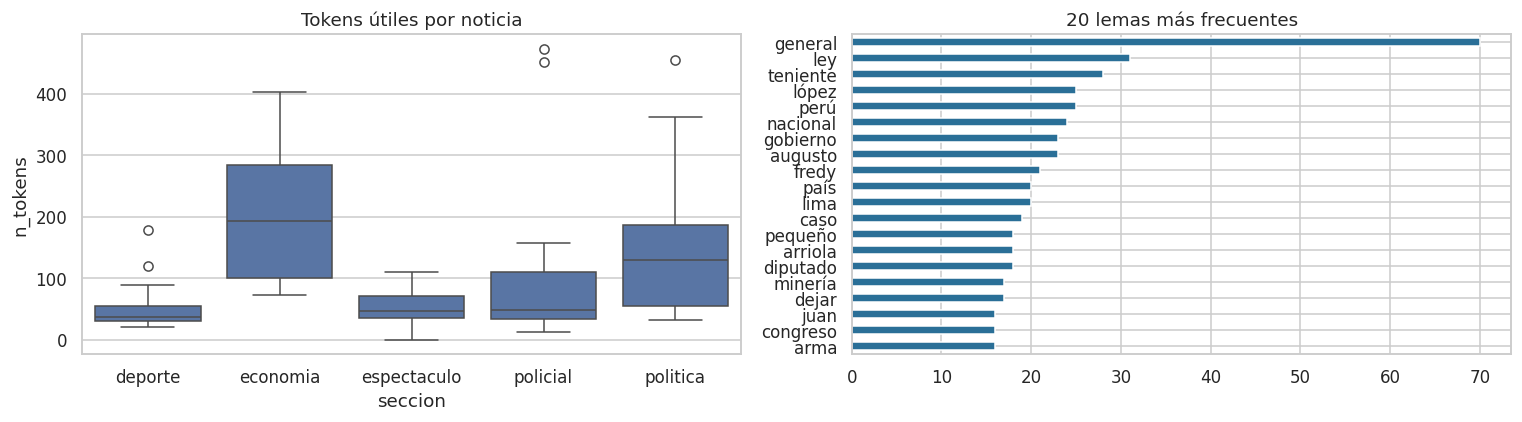

Reducción de vocabulario: 5516 palabras → 4224 lemas


In [12]:
from collections import Counter
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df, x='seccion', y='n_tokens', ax=ax[0]); ax[0].set_title('Tokens útiles por noticia')
top = Counter(t for ts in df.tokens for t in ts).most_common(20)
pd.Series(dict(top)).sort_values().plot.barh(ax=ax[1], color='#2a6f97', title='20 lemas más frecuentes')
plt.tight_layout(); plt.show()
print(f"Reducción de vocabulario: {df.texto_limpio.str.split().explode().nunique()} palabras → "
      f"{df.tokens.explode().nunique()} lemas")

## 5. NLP
### 5.1 Clasificación temática
Se comparan dos enfoques con las secciones del periódico como etiqueta real:
1. **Supervisado:** TF-IDF + Regresión Logística / Naive Bayes / SVM lineal, evaluados con validación cruzada estratificada (el dataset es pequeño, así que no se separa un test fijo).
2. **Zero-shot:** modelo multilingüe `mDeBERTa-v3-base-mnli-xnli`, sin entrenamiento.

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, f1_score, accuracy_score, ConfusionMatrixDisplay

X, y = df.tokens_str, df.seccion
k = min(5, y.value_counts().min()); cv = StratifiedKFold(k, shuffle=True, random_state=42)
tfidf = lambda: TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True, max_features=5000)
modelos = {
    'LogReg':      Pipeline([('tfidf', tfidf()), ('clf', LogisticRegression(C=5, max_iter=2000, class_weight='balanced'))]),
    'NaiveBayes':  Pipeline([('tfidf', tfidf()), ('clf', MultinomialNB(alpha=0.3))]),
    'LinearSVC':   Pipeline([('tfidf', tfidf()), ('clf', LinearSVC(C=1, class_weight='balanced'))]),
}
resultados, preds = [], {}
for nom, m in modelos.items():
    p = cross_val_predict(m, X, y, cv=cv); preds[nom] = p
    resultados.append({'modelo': nom, 'accuracy': accuracy_score(y, p), 'F1_macro': f1_score(y, p, average='macro')})
pd.DataFrame(resultados).round(3)

,modelo,accuracy,F1_macro
0,LogReg,0.756,0.736
1,NaiveBayes,0.695,0.622
2,LinearSVC,0.780,0.781


In [16]:
from transformers import pipeline as hf_pipeline
zsc = hf_pipeline('zero-shot-classification', model='MoritzLaurer/mDeBERTa-v3-base-mnli-xnli', device=0)

ETIQ = {'politica': 'política', 'economia': 'economía', 'policial': 'crimen y sucesos policiales',
        'deporte': 'deportes', 'espectaculo': 'espectáculos y farándula'}
ETIQ = {k: v for k, v in ETIQ.items() if k in set(df.seccion)}
inv = {v: k for k, v in ETIQ.items()}
etiquetas = list(ETIQ.values())

# --- Diagnóstico ---
print('Secciones en los archivos:', sorted(df.seccion.unique()))
print('Etiquetas zero-shot:', etiquetas)
vacios = df.texto_reparado.fillna('').str.strip().str.len() < 20
print(f'Noticias sin texto útil (OCR falló): {vacios.sum()}')
if vacios.any(): display(df.loc[vacios, ['archivo', 'confianza']])
assert etiquetas, 'ETIQ quedó vacío: las secciones de los archivos no coinciden con las claves de ETIQ'

# --- Clasificación, una noticia a la vez ---
def zero_shot(texto):
    texto = (texto or '').strip()[:1500]
    if len(texto) < 20:
        return 'sin_texto'          # cuenta como error en las métricas
    o = zsc(texto, etiquetas, hypothesis_template='Esta noticia trata sobre {}.')
    return inv[o['labels'][0]]

preds['ZeroShot'] = [zero_shot(t) for t in df.texto_reparado]
resultados = [r for r in resultados if r['modelo'] != 'ZeroShot']   # por si re-ejecutas la celda
resultados.append({'modelo': 'ZeroShot', 'accuracy': accuracy_score(y, preds['ZeroShot']),
                   'F1_macro': f1_score(y, preds['ZeroShot'], average='macro', labels=list(ETIQ))})
tabla_clf = pd.DataFrame(resultados).sort_values('F1_macro', ascending=False).round(3)
display(tabla_clf)

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Secciones en los archivos: ['deporte', 'economia', 'espectaculo', 'policial', 'politica']
Etiquetas zero-shot: ['política', 'economía', 'crimen y sucesos policiales', 'deportes', 'espectáculos y farándula']
Noticias sin texto útil (OCR falló): 1


,archivo,confianza
45,espectaculo_4.jpeg,0.0


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,modelo,accuracy,F1_macro
2,LinearSVC,0.780,0.781
0,LogReg,0.756,0.736
3,ZeroShot,0.695,0.635
1,NaiveBayes,0.695,0.622


Mejor: LinearSVC

              precision    recall  f1-score   support

     deporte      0.778     0.913     0.840        23
    economia      1.000     0.667     0.800         6
 espectaculo      0.708     0.773     0.739        22
    policial      0.800     0.667     0.727        18
    politica      0.833     0.769     0.800        13

    accuracy                          0.780        82
   macro avg      0.824     0.758     0.781        82
weighted avg      0.789     0.780     0.779        82



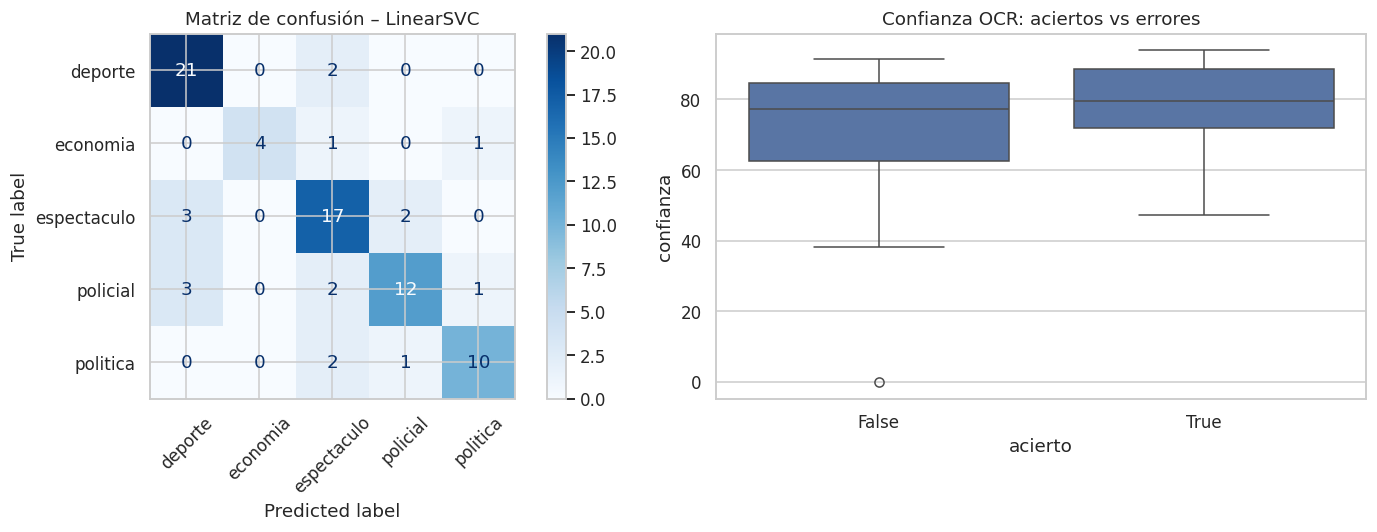

In [18]:
MEJOR_CLF = tabla_clf.iloc[0].modelo
print(f'Mejor: {MEJOR_CLF}\n'); print(classification_report(y, preds[MEJOR_CLF], digits=3))
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay.from_predictions(y, preds[MEJOR_CLF], ax=ax[0], cmap='Blues', xticks_rotation=45)
ax[0].set_title(f'Matriz de confusión – {MEJOR_CLF}')
# ¿Los errores de clasificación vienen de un mal OCR?
df['acierto'] = np.array(preds[MEJOR_CLF]) == y
sns.boxplot(data=df, x='acierto', y='confianza', ax=ax[1]); ax[1].set_title('Confianza OCR: aciertos vs errores')
plt.tight_layout(); plt.show()

In [19]:
# Modelo final ligero para la app (se entrena con todo el dataset)
import joblib
final = modelos['LogReg'].fit(X, y)
joblib.dump(final, MOD/'clasificador_tfidf_logreg.joblib')
# Términos más influyentes por sección (interpretabilidad)
vec, clf = final.named_steps['tfidf'], final.named_steps['clf']; vocab = vec.get_feature_names_out()
pd.DataFrame({c: vocab[np.argsort(clf.coef_[i])[::-1][:10]] for i, c in enumerate(clf.classes_)})

,deporte,economia,espectaculo,policial,politica
0,club,minería,amor,arma,voto
1,clausura,pequeño,cantante,san,elección
2,fecha,pequeño minería,sentir,arma fuego,lula
3,perder,artesanal,feliz,fuego,diputado
4,equipo,presupuesto,smith,adolescente,cámara
5,balón,ministerio,show,dajo sai,votar
6,partido,destinado,arrasar,dajo,flávio
7,copa,pensión,contar,ción anotar,país
8,torneo,contraloría,ver,nacer,perú
9,ganar,drén,película,ción,constitución


> Si el zero-shot gana en F1 pero el TF-IDF queda cerca, se despliega el TF-IDF (pesa KB y responde en milisegundos). Si la diferencia es grande, se puede desplegar el zero-shot aceptando mayor latencia.

### 5.2 Extracción de entidades (NER) y regiones del Perú

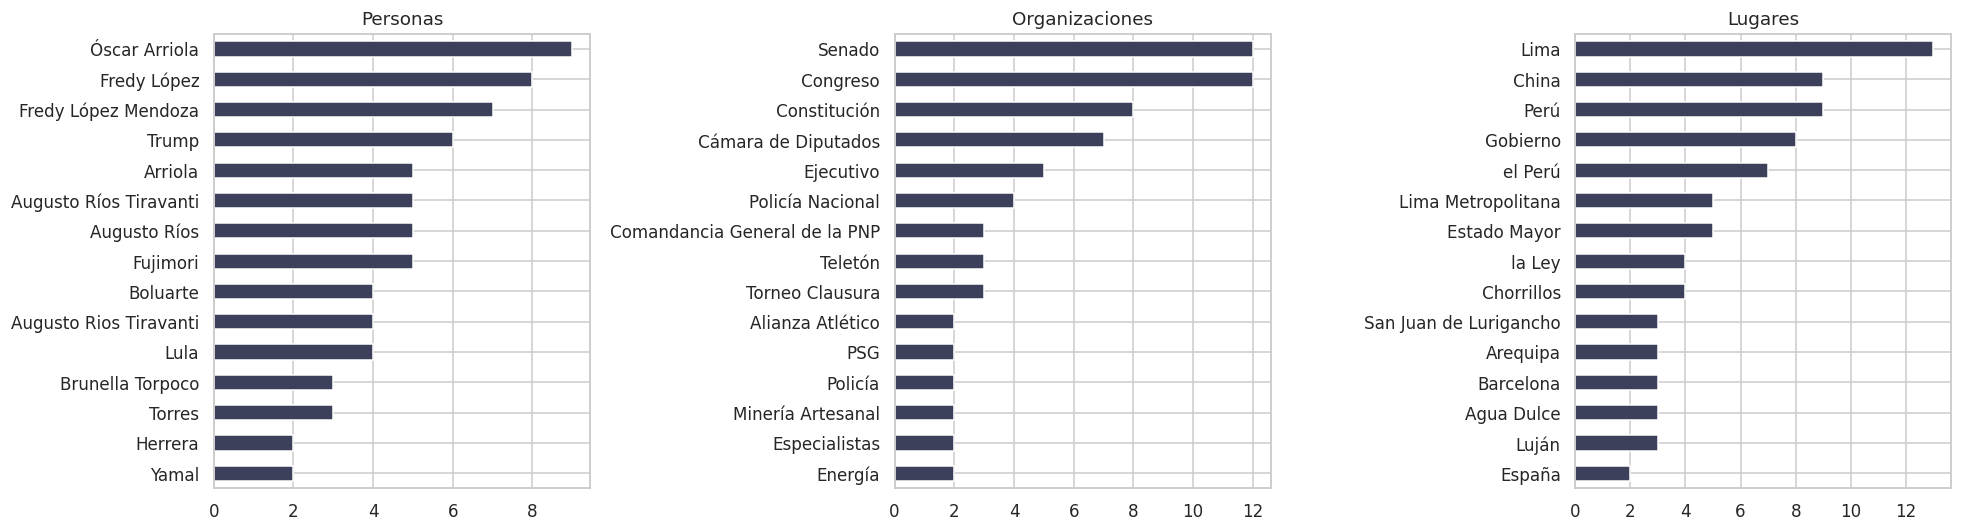

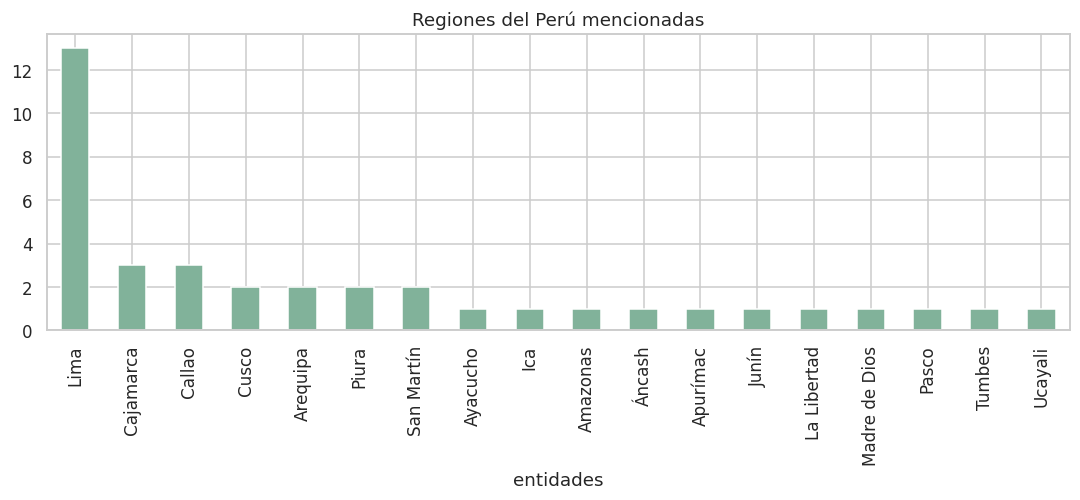

In [20]:
df['entidades'] = df.texto_reparado.apply(lambda t: U.extraer_entidades(t, nlp))
def top_ent(tipo, n=15):
    c = Counter()
    for e in df.entidades: c.update(dict(e[tipo]))
    return pd.Series(dict(c.most_common(n)))
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, (tipo, tit) in zip(ax, [('PER', 'Personas'), ('ORG', 'Organizaciones'), ('LOC', 'Lugares')]):
    top_ent(tipo).sort_values().plot.barh(ax=a, color='#3d405b', title=tit)
plt.tight_layout(); plt.show()

reg = df.entidades.apply(lambda e: e['REGIONES_PERU']).explode().dropna()
reg.value_counts().plot.bar(figsize=(12, 3.5), color='#81b29a', title='Regiones del Perú mencionadas'); plt.show()

### 5.3 Palabras clave (TF-IDF) por sección

In [21]:
tf = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(df.tokens_str)
joblib.dump(tf, MOD/'tfidf_keywords.joblib')
df['palabras_clave'] = df.tokens_str.apply(lambda t: [w for w, _ in U.palabras_clave(t, tf, 8)])
M = pd.DataFrame(tf.transform(df.tokens_str).toarray(), columns=tf.get_feature_names_out())
M['seccion'] = df.seccion.values
M.groupby('seccion').mean().apply(lambda r: ', '.join(r.nlargest(10).index), axis=1).to_frame('top_keywords')

,top_keywords
seccion,
deporte,"clausura, fecha, club, partido, perder, ganar,..."
economia,"minería, pequeño, pequeño minería, artesanal, ..."
espectaculo,"amor, cantante, contar, feliz, él, sentir, sho..."
policial,"arma, adolescente, san, fuego, arma fuego, lim..."
politica,"voto, elección, diputado, lula, perú, cámara, ..."


### 5.4 Resumen automático (extractivo)

In [22]:
df['resumen'] = df.texto_reparado.apply(lambda t: U.resumen_extractivo(t, nlp, 2))
df['compresion'] = df.resumen.str.len() / df.texto_reparado.str.len().clip(lower=1)
for _, r in df.sample(3, random_state=1).iterrows():
    print(f"[{r.seccion} – {r.diario}]\n{r.resumen}\n")
print(f"Compresión media: {df.compresion.mean():.0%} del texto original")

[deporte – sin_dato]
e e" "Y die dl: Pe pu ARE ree SN

-: y e. ¡ ROJINEGROS MOTIVADOS '* -- "León" vuelve..,="

O A A 3 pc ¡CUGAT Tere p A E: BERNARDO CUESTA y FBC ' Y: Melgar no renuncian al sueño de An y Ñ conquistar el Torneo Clausura. E - Tras vencer aUTCen Cajamarca, A EN el Dominó yaapuntaasu siguien- Y a y CAN A te desafío: Comerciantes Unidos, pl f AS y + - este jueves en Arequipa, donde ** 4 4 "0.

[politica – sin_dato]
Dicequeel Senado ha dado la ley, no el Congreso. Si el Senado no deja legislar a Diputados, Diputados puede no dejar gobernar a Fujimori.

[espectaculo – sin_dato]
o, A 25 y 94 Y vr Y AS = " ¿Y "e E SS? - " Uno D 1 Este año esperan más de nueve millones de soles

[hace fuerza! por la Teletón

Christian Rivero anunció que este 11 y 12 de setiembre arranca la jornada solidaria de la Teletón, que busca alcanzar la meta de más de nueve millones de soles. Resaltó que los protagonistas de esta campaña son las 'historias de las familias y pequeños; a raíz de que se ha

### 5.5 Nube de palabras por sección

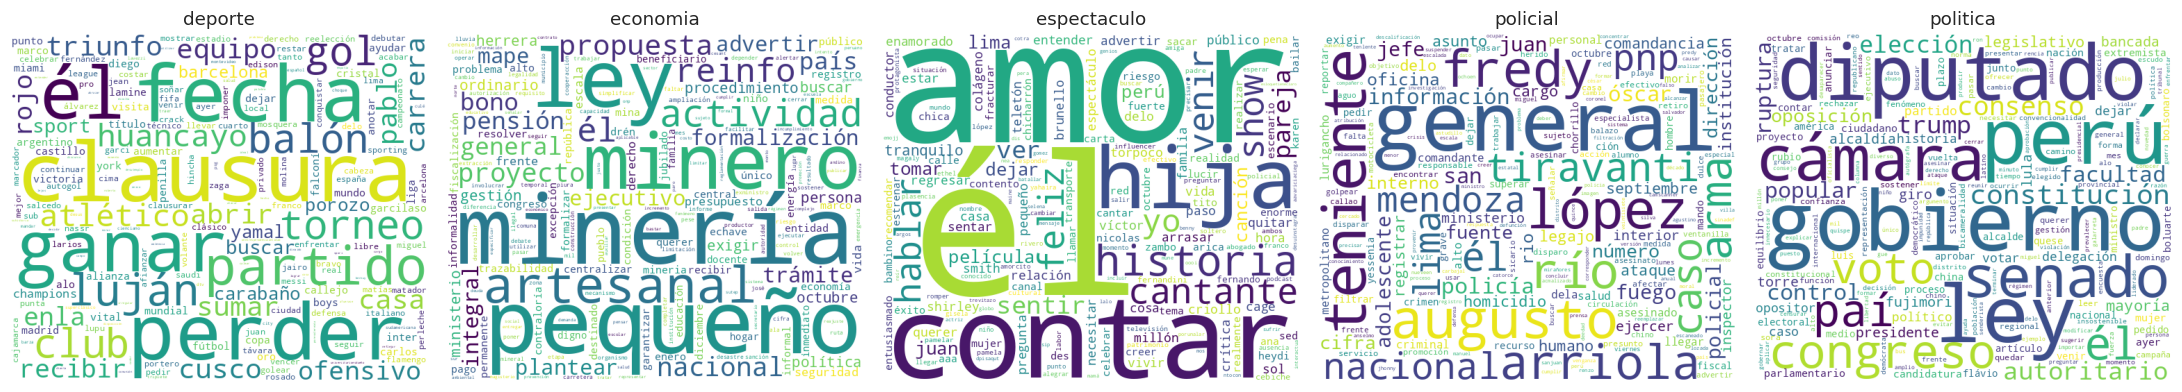

In [23]:
from wordcloud import WordCloud
secs = sorted(df.seccion.unique())
fig, axs = plt.subplots(1, len(secs), figsize=(4 * len(secs), 4))
for ax, s in zip(np.atleast_1d(axs), secs):
    wc = WordCloud(width=600, height=500, background_color='white', colormap='viridis', collocations=False)
    ax.imshow(wc.generate(' '.join(df.loc[df.seccion == s, 'tokens_str']))); ax.set_title(s); ax.axis('off')
plt.tight_layout(); plt.show()

## 6. Exportar resultados

In [24]:
cols = ['archivo', 'seccion', 'diario', 'confianza', 'n_palabras', 'texto_reparado',
        'resumen', 'palabras_clave', 'acierto']
df[cols].to_csv(OUT/'resultados_nlp.csv', index=False, encoding='utf-8-sig')
df[cols + ['entidades']].to_json(OUT/'resultados_nlp.json', orient='records', force_ascii=False, indent=2)
tabla_var.to_csv(OUT/'experimento_preprocesamiento.csv'); tabla_clf.to_csv(OUT/'comparacion_clasificadores.csv', index=False)
print('Listo:', list(OUT.iterdir()))

Listo: [PosixPath('/content/drive/My Drive/Universidad/10mo ciclo/CDII/CDII_OCR_Periodicos/outputs/ocr_crudo.csv'), PosixPath('/content/drive/My Drive/Universidad/10mo ciclo/CDII/CDII_OCR_Periodicos/outputs/resultados_nlp.csv'), PosixPath('/content/drive/My Drive/Universidad/10mo ciclo/CDII/CDII_OCR_Periodicos/outputs/resultados_nlp.json'), PosixPath('/content/drive/My Drive/Universidad/10mo ciclo/CDII/CDII_OCR_Periodicos/outputs/experimento_preprocesamiento.csv'), PosixPath('/content/drive/My Drive/Universidad/10mo ciclo/CDII/CDII_OCR_Periodicos/outputs/comparacion_clasificadores.csv')]


## 7. Conclusiones, limitaciones y mejoras
*(Completar con sus números)*

**Hallazgos**
- Preprocesamiento: la variante ___ redujo el CER de ___ (solo gris) a ___. El paso que más aportó fue ___.
- OCR: Tesseract obtuvo CER ___ vs EasyOCR ___, con tiempos de ___ s vs ___ s.
- Clasificación: el mejor modelo fue ___ (F1-macro = ___). La sección más confundida fue ___ con ___ porque ___.
- Los errores de clasificación se concentran / no se concentran en imágenes con baja confianza de OCR.

**Limitaciones**
- Dataset pequeño (___ imágenes) y con ___ diarios; el clasificador puede no generalizar a otros medios.
- Notas con varias columnas o fotos incrustadas desordenan el texto extraído.
- El NER de spaCy no está entrenado con nombres peruanos y falla con ___.
- El resumen extractivo depende de que el OCR conserve los puntos finales.

**Mejoras futuras**
- Detección de layout (columnas) antes del OCR, p. ej. con PaddleOCR o LayoutParser.
- Ampliar el dataset con portadas digitales y notas web.
- Ajuste fino (fine-tuning) de un modelo BETO/RoBERTa en español con más noticias etiquetadas.

In [25]:
import json, sklearn
json.dump({'preprocesamiento': CFG, 'variante': MEJOR, 'psm': 3}, open(MOD/'config_preproc.json', 'w'), indent=2)
print('scikit-learn', sklearn.__version__, '| spaCy', spacy.__version__)

scikit-learn 1.6.1 | spaCy 3.8.16
